In [2]:
from genshin_build_checker.data import load_builds

builds = load_builds("data/builds.csv")
len(builds)

14

In [3]:
import pandas as pd 
from genshin_build_checker.rater import crit_value

valid = [b for b in builds if b.atk > 0 and b.crit_rate <= 1]

df = pd.DataFrame({
    "character": [b.character for b in valid],
    "crit_value": [crit_value(b) for b in valid],
    "good":  [b.good for b in valid]
})
df

,character,crit_value,good
0,Furina,3.2,1
1,Nahida,2.8,1
2,Raiden,3.1,1
3,Neuvillette,3.3,1
4,Kazuha,1.1,0
5,Bennett,0.9,0
6,Xiangling,2.2,0
7,Xingqiu,1.9,0
8,Hu Tao,3.6,1
9,Yelan,3.2,1


<function matplotlib.pyplot.show(close=None, block=None)>

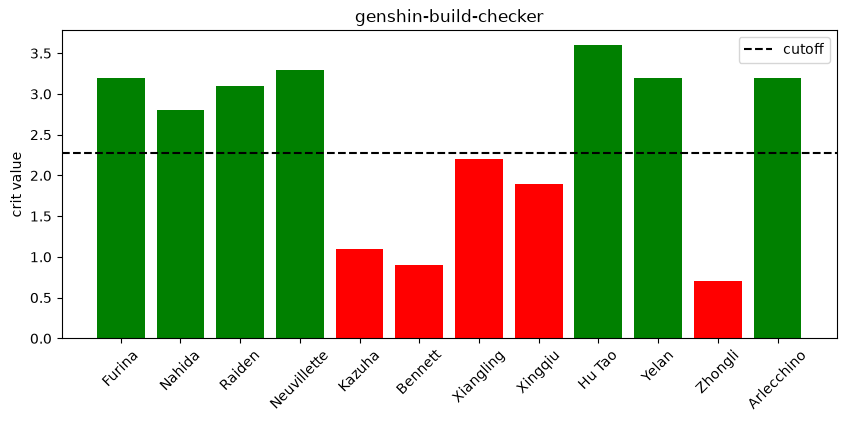

In [4]:
import matplotlib.pyplot as plt

colors = ["green" if g == 1 else "red" for g in df["good"]]

plt.figure(figsize=(10, 4))
plt.bar(df["character"], df["crit_value"], color=colors)
plt.axhline(2.27, linestyle="--", color="black", label="cutoff")
plt.ylabel("crit value")
plt.title("genshin-build-checker")
plt.xticks(rotation=45)
plt.legend()
plt.show